In [17]:
from langgraph.graph import StateGraph, END
import random
from typing import Dict, List, TypedDict

class AgentState(TypedDict):
    name: str
    target_number: int
    current_guess: int

In [18]:
def greeter(state: AgentState) -> AgentState:
    print(f"Hey {state['name']}! The chosen number to guess is {state['target_number']}.")
    return state

def guesser(state: AgentState) -> AgentState:
    print(f"\n current_guess: {state['current_guess']}")
    if state['target_number'] > state['current_guess']:
        state['current_guess'] += 1
    elif state['target_number'] < state['current_guess']:
        state['current_guess'] -= 1
    return state

def number_found(state: AgentState) -> str:
    if state['target_number'] == state['current_guess']:
        return 'found'
    else:
        return 'not_found'

def op_setter(state: AgentState) -> AgentState:
    print(f"The guessed number is {state['current_guess']}. Thank you!")
    return state

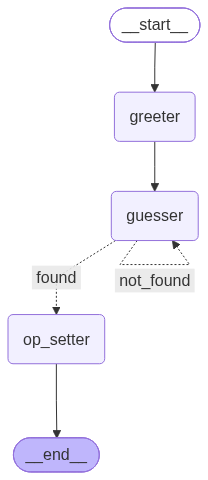

In [21]:
from langgraph.graph import START


graph = StateGraph(AgentState)
graph.add_node('greeter', greeter)
graph.add_node('guesser', guesser)
graph.add_node('op_setter', op_setter)
graph.add_edge('greeter', 'guesser')
graph.add_edge(START, 'greeter')
graph.add_edge('op_setter', END)

graph.add_conditional_edges(
    "guesser",        # Source node
    number_found, # Routing function
    {
        "found": "op_setter",  # Self-loop back to same node
        "not_found": 'guesser'        # End the graph
    }
)

app = graph.compile()


from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [23]:
app.invoke({
    "name": "Kapil",
    "target_number": random.randint(1, 25),
    "current_guess": random.randint(1, 25)
})

Hey Kapil! The chosen number to guess is 18.

 current_guess: 10

 current_guess: 11

 current_guess: 12

 current_guess: 13

 current_guess: 14

 current_guess: 15

 current_guess: 16

 current_guess: 17
The guessed number is 18. Thank you!


{'name': 'Kapil', 'target_number': 18, 'current_guess': 18}